In [2]:
#Importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from datasets import load_dataset

#Loading the data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

#Cleaning the date and skills columns
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\amire\anaconda3\envs\python_course\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
# Defining countries that we will filter with
mena_countries = ['Sudan','Egypt', 'Kuwait', 'Saudi Arabia', 'Jordan', 'United Arab Emirates', 'Lebanon', 'Libya', 'Syria', 'Qatar', 'Iraq',
                   'Morocco', 'Palestine', 'Algeria', 'Tunisia', 'Bahrain', 'Oman', 'Yemen'  ]

# Defining job roles
job_roles = ['Data Analyst', 'Data Engineer', 'Data Scientist']

# Filtering data frame to have only the three main data roles in mena region countries
df_mena = df[(df['job_country'].isin(mena_countries)) & (df['job_title_short'].isin(job_roles))]

df_mena['job_country'].unique()
# There are no job postings from Syria

<ArrowStringArray>
[               'Sudan',         'Saudi Arabia', 'United Arab Emirates',
              'Tunisia',              'Lebanon',                 'Oman',
               'Kuwait',               'Jordan',                'Egypt',
              'Morocco',                 'Iraq',                'Qatar',
              'Bahrain',                'Yemen',                'Libya',
            'Palestine',              'Algeria']
Length: 17, dtype: str

Text(0.5, 1.0, 'Top 10 location of the top 3 data roles in mena region')

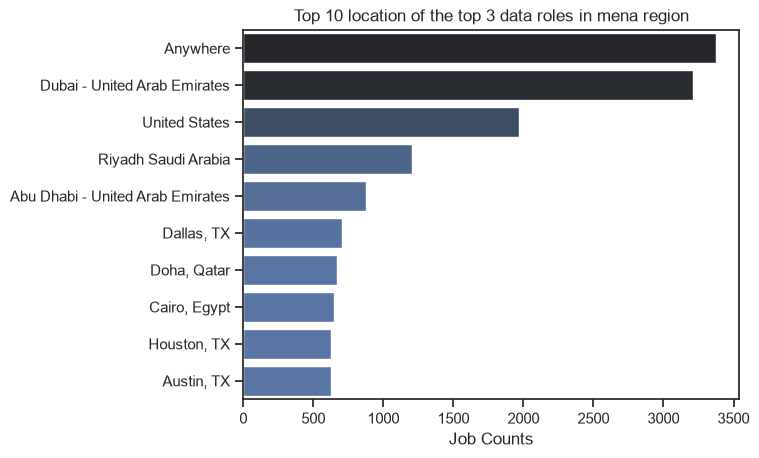

In [4]:
df_plot = df_mena['job_location'].value_counts().head(10).to_frame()

sns.set_theme(style= 'ticks')
sns.barplot(data = df_plot, x= 'count', y= 'job_location', hue = 'count', legend= False, palette= 'dark:b_r')
plt.ylabel('')
plt.xlabel('Job Counts')
plt.title('Top 10 location of the top 3 data roles in mena region')

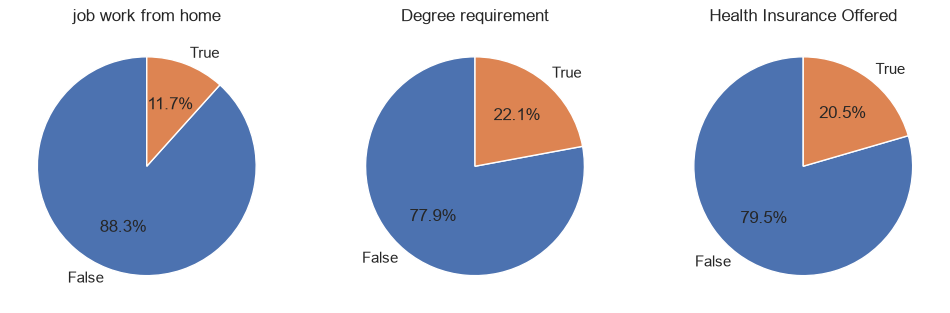

In [5]:
column_and_title = {'job_work_from_home':'job work from home', 
                    'job_no_degree_mention':'Degree requirement',
                    'job_health_insurance':'Health Insurance Offered'
                    }

fig,ax = plt.subplots(1,3)
fig.set_size_inches((12,5))
for i,(column,title) in enumerate(column_and_title.items()):
    ax[i].pie(df_mena[column].value_counts(), labels = [False, True], autopct = '%1.1f%%', startangle = 90)
    ax[i].set_title(title)


Text(0.5, 1.0, 'Top 10 Companies of the top 3 data roles in MENA region')

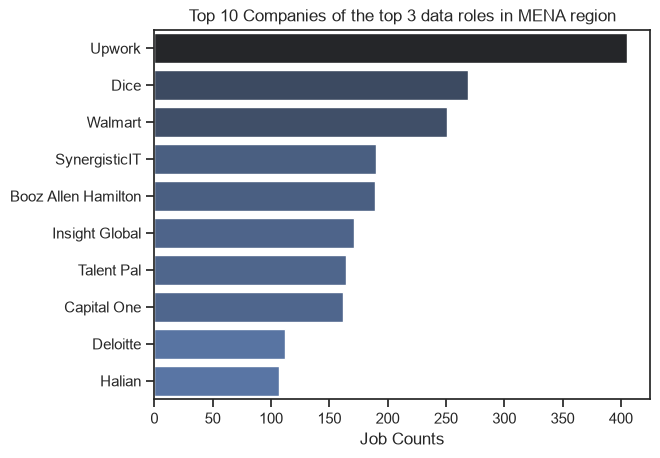

In [6]:
df_plot = df_mena['company_name'].value_counts().head(10).to_frame()

sns.set_theme(style= 'ticks')
sns.barplot(data = df_plot, x= 'count', y= 'company_name', hue = 'count', legend= False, palette = 'dark:b_r')
plt.ylabel('')
plt.xlabel('Job Counts')
plt.title('Top 10 Companies of the top 3 data roles in MENA region')